<a href="https://colab.research.google.com/github/helenamoisme/ai-hw1-puzzle/blob/main/sign_language.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [57]:
#Helena Mo UNI:hm3194

Name and UNI # TODO: Replace this with your name and UNI

# MNIST Sign Language

In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics         import accuracy_score
from sklearn.model_selection import train_test_split

import keras
from keras.utils  import to_categorical
from keras.models import Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D, Flatten, Dropout

In [59]:
class SignLanguage:
    def __init__(self):
        self.model = None

        self.data = {
            "train": None,
            "test" : None
        }
        self.create_model()

    def create_model(self):
        """
        Create a CNN model and save it to self.model
        """
        model = Sequential()
        model.add(keras.Input(shape=(28, 28, 1)))
        model.add(Conv2D(32, (3, 3), activation='relu'))
        model.add(MaxPooling2D((2, 2)))
        model.add(Conv2D(64, (3, 3), activation='relu'))
        model.add(MaxPooling2D((2, 2)))
        model.add(Flatten())
        model.add(Dropout(0.3))
        model.add(Dense(25, activation='softmax'))
        model.compile(optimizer='adam', loss=keras.losses.categorical_crossentropy, metrics=['accuracy'])

        self.model = model

    def prepare_data(self, images, labels):
        """
        Use this method to normalize the dataset and split it into training and validation sets.
        Save your data in self.data["train"] and self.data["test"] as a tuple
        of (images, labels). Note: self.data["test"] holds your VALIDATION set,
        not the real test set (the grading script keeps that separate).

        :param images numpy array of size (num_examples, 28*28)
        :param labels numpy array of size (num_examples, )
        """
        images = images.astype('float32')
        images = images / 255.0
        images = images.reshape(len(images), 28, 28, 1)

        x_train, x_val, y_train, y_val = train_test_split(
            images, labels,
            test_size=0.2,
            random_state=42,
            stratify=labels
        )

        y_train = to_categorical(y_train, num_classes=25)
        y_val = to_categorical(y_val, num_classes=25)

        self.data = {
            "train": (x_train, y_train),
            "test" : (x_val, y_val)
        }

    def train(self, batch_size:int=128, epochs:int=30, verbose:int=1):
        """
        Use model.fit() to train your model. Make sure to return the history for a neat visualization.
        Pass your validation set to model.fit() (validation_data=...), so the history
        contains 'val_accuracy' for visualize_accuracy().

        :param batch_size The batch size to use for training
        :param epochs     Number of epochs to use for training
        :param verbose    Whether or not to print training output
        """
        x_train, y_train = self.data["train"]
        x_val, y_val = self.data["test"]

        history = self.model.fit(
            x_train, y_train,
            batch_size=batch_size,
            epochs=epochs,
            verbose=verbose,
            validation_data=(x_val, y_val)
        )
        return history

    def predict(self, data):
        """
        Use the trained model to predict labels for test data.

        :param data: numpy array of size (num_examples, 28*28), raw pixel values 0-255
        :return a numpy array of integer class labels (0 to 24). array size = (num_examples, )
        """
        images = data.astype('float32')
        images = images / 255.0
        images = images.reshape(len(images), 28, 28, 1)

        probabilities = self.model.predict(images, verbose=0)
        predictions = np.argmax(probabilities, axis=1)
        return predictions

    def visualize_data(self, data):
        """
        Visualizing the hand gestures

        :param data: tuple containing (images, labels) or list of images
        """
        if data is None: return

        # Unpack if a tuple is passed
        if isinstance(data, tuple):
            images = data[0]
        else:
            images = data

        nrows, ncols = 5, 5
        fig, axs = plt.subplots(nrows, ncols, figsize=(10, 10), sharex=True, sharey=True)
        plt.subplots_adjust(wspace=0, hspace=0)

        for i in range(nrows):
            for j in range(ncols):
                axs[i][j].imshow(images[i*ncols+j].reshape(28, 28), cmap='gray')
        plt.show()

    def visualize_accuracy(self, history):
        """
        Plots out the accuracy measures given a keras history object

        :param history: return value from model.fit()
        """
        if history is None: return

        plt.plot(history.history['accuracy'])
        plt.plot(history.history['val_accuracy'])
        plt.title("Accuracy")
        plt.xlabel('epoch')
        plt.ylabel('accuracy')
        plt.legend(['train','validation'])
        plt.show()

# Grading Script

Do NOT modify this section

In [60]:
if __name__=="__main__":
    train = pd.read_csv('train.csv')
    test  = pd.read_csv('test.csv')

    train_labels, test_labels = train['label'].values, test['label'].values
    train.drop('label', axis=1, inplace=True)
    test.drop('label', axis=1, inplace=True)

    # Cast to standard Python int to satisfy Keras strict type checking
    num_classes = int(test_labels.max() + 1)
    train_images, test_images = train.values, test.values

    print(train_images.shape, train_labels.shape, test_images.shape, test_labels.shape)

(27455, 784) (27455,) (7172, 784) (7172,)


In [61]:
if __name__=="__main__":
    my_model = SignLanguage()
    my_model.prepare_data(train_images, train_labels)

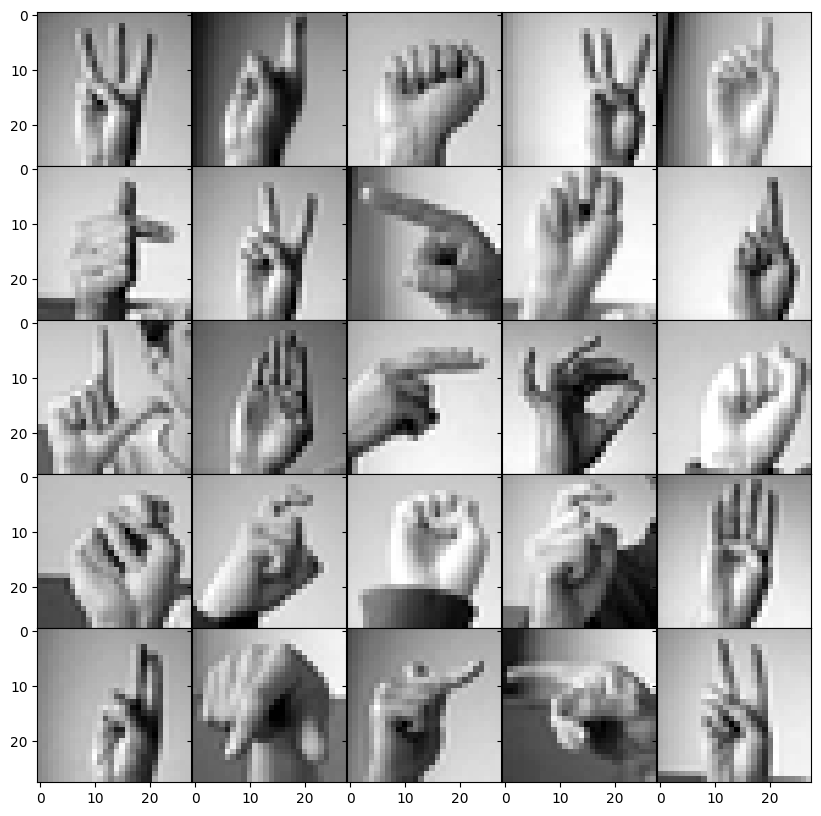

In [62]:
if __name__=="__main__":
    my_model.visualize_data(my_model.data["train"])

Epoch 1/30
172/172 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.4013 - loss: 2.0968 - val_accuracy: 0.7536 - val_loss: 0.8832
Epoch 2/30
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8016 - loss: 0.6571 - val_accuracy: 0.9011 - val_loss: 0.3711
Epoch 3/30
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8988 - loss: 0.3329 - val_accuracy: 0.9636 - val_loss: 0.1696
Epoch 4/30
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9473 - loss: 0.1876 - val_accuracy: 0.9863 - val_loss: 0.0900
Epoch 5/30
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9707 - loss: 0.1164 - val_accuracy: 0.9949 - val_loss: 0.0474
Epoch 6/30
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9811 - loss: 0.0792 - val_accuracy: 0.9987 - val_loss: 0.0290
Epoch 7/30
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9864 - loss: 0.0583 - val_accuracy: 0.9996 - val_loss: 0.0163
Epoch 8/30
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9900 - loss: 0.0423 - val_accuracy: 0

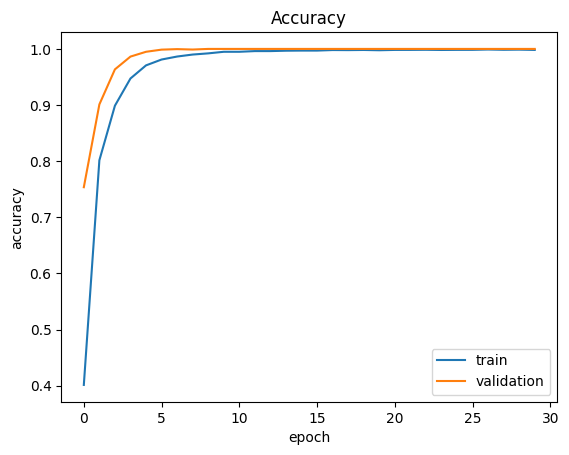

In [63]:
if __name__=="__main__":
    history = my_model.train(epochs=30, verbose=1)
    my_model.visualize_accuracy(history)

In [64]:
if __name__=="__main__":
    y_pred = my_model.predict(test_images)
    accuracy = accuracy_score(test_labels, y_pred)
    print(accuracy)

0.9329336307863916
